In [21]:
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
from PIL import Image
from tqdm import tqdm
from pillow_heif import register_heif_opener
from IPython.display import display, HTML
import numpy as np
import cv2

from pathlib import Path
from IPython.display import display, HTML
from pillow_heif import register_heif_opener

import matplotlib.pyplot as plt

register_heif_opener()


SCREWS_DIR = Path("../data/raw/screws")  # your folder
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".heic"}

def list_images(folder: Path):
    return [p for p in folder.rglob("*") if p.suffix.lower() in EXTS and p.is_file()]

def open_bgr(p: Path):
    pil = Image.open(p).convert("RGB")
    bgr = cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)
    return bgr, pil


In [ ]:
def find_screw_candidates_hough(bgr, max_side=1600):
    """
    Returns circles as (x,y,r) in image coordinates.
    Downscales for speed but returns coords in original scale.
    """
    H, W = bgr.shape[:2]
    scale = max_side / max(H, W)
    if scale < 1.0:
        small = cv2.resize(bgr, (int(W*scale), int(H*scale)), interpolation=cv2.INTER_AREA)
    else:
        small = bgr
        scale = 1.0

    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (7, 7), 0)

    # HoughCircles params: these are “starter” values
    circles = cv2.HoughCircles(
        gray,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=20,
        param1=120,     # Canny high threshold internally
        param2=28,      # accumulator threshold (lower -> more detections)
        minRadius=4,
        maxRadius=40
    )

    out = []
    if circles is not None:
        circles = np.round(circles[0]).astype(int)
        for (x, y, r) in circles:
            # back to original coordinates
            x0 = int(x / scale)
            y0 = int(y / scale)
            r0 = int(r / scale)
            out.append((x0, y0, r0))

    return out


In [ ]:
def loose_score_for_circle(bgr, circle, pad=1.6):
    """
    circle=(x,y,r). Returns score in [0,1-ish] (higher => more likely loose).
    """
    x, y, r = circle
    H, W = bgr.shape[:2]

    R = max(6, int(r * pad))
    x1, y1 = max(0, x - R), max(0, y - R)
    x2, y2 = min(W, x + R), min(H, y + R)
    crop = bgr[y1:y2, x1:x2]
    if crop.size == 0:
        return 0.0, None

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5,5), 0)

    ch, cw = gray.shape
    cy, cx = ch // 2, cw // 2
    rr = int(min(ch, cw) * 0.22)  # approximate head radius in crop coords

    # edges
    edges = cv2.Canny(gray, 60, 160)

    yy, xx = np.ogrid[:ch, :cw]
    d2 = (yy - cy) ** 2 + (xx - cx) ** 2

    # ring around head boundary
    ring = (d2 <= (rr+3)**2) & (d2 >= (rr-3)**2)
    ring_edge = edges[ring].mean() / 255.0 if ring.any() else 0.0

    # outer ring for “shadow gap”
    outer = (d2 <= (rr+10)**2) & (d2 >= (rr+4)**2)
    if outer.any():
        p25 = np.percentile(gray, 25)
        shadow = (gray[outer] < p25).mean()
    else:
        shadow = 0.0

    score = 0.6 * ring_edge + 0.4 * shadow
    return float(score), crop


In [29]:
LOOSE_THRESH = 0.28   # starter; lower => more “defects” flagged
MAX_SHOW = 50         # show up to N images

paths = list_images(SCREWS_DIR)
print("Found:", len(paths), "images in", SCREWS_DIR)

results = []
shown = 0

for p in tqdm(paths):
    bgr, pil = open_bgr(p)
    circles = find_screw_candidates_hough(bgr)

    best = 0.0
    best_circle = None

    for c in circles:
        s, _ = loose_score_for_circle(bgr, c)
        if s > best:
            best, best_circle = s, c

    defective = (best >= LOOSE_THRESH) and (best_circle is not None)

    results.append({
        "path": str(p),
        "num_candidates": len(circles),
        "best_score": best,
        "defective": defective
    })

    # Visualize
    if shown < MAX_SHOW:
        vis = bgr.copy()
        if best_circle is not None:
            x, y, r = best_circle
            cv2.circle(vis, (x, y), r, (0, 255, 0), 2)
            cv2.circle(vis, (x, y), 2, (0, 255, 0), 2)
            cv2.putText(vis, f"best={best:.3f}  {'DEFECT' if defective else 'ok'}",
                        (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0,255,0), 2)

        vis_rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
        display(HTML(f"<b>{p.name}</b> | candidates={len(circles)} | best={best:.3f} | defective={defective}"))
        display(Image.fromarray(vis_rgb))
        shown += 1

df = pd.DataFrame(results)
df.to_csv("../outputs/screw_defects_report.csv", index=False)
print("Saved report: screw_defects_report.csv")
df.sort_values("best_score", ascending=False).head(10)


Found: 0 images in screws


0it [00:00, ?it/s]

Saved report: screw_defects_report.csv


KeyError: 'best_score'

In [30]:
def plot_all_candidates(bgr, candidates, max_draw=20):
    # draw on a copy
    vis = bgr.copy()
    draw_list = candidates[:max_draw]

    for i, (x, y, r) in enumerate(draw_list):
        cv2.circle(vis, (x, y), r, (0, 255, 0), 2)
        cv2.putText(vis, str(i), (x + r + 2, y + r + 2),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

    rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(14, 8))
    plt.imshow(rgb)
    plt.title(f"Candidates: {len(candidates)} (drawn: {len(draw_list)})")
    plt.axis("off")
    plt.show()


In [31]:
SCREWS_DIR = Path("../data/raw/screws")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".heic"}

def list_images(folder: Path):
    return [p for p in folder.rglob("*") if p.suffix.lower() in EXTS and p.is_file()]

def open_bgr(p: Path):
    pil = Image.open(p).convert("RGB")
    bgr = cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)
    return bgr

def build_blob_detector():
    params = cv2.SimpleBlobDetector_Params()

    # These are starter values; we’ll tune after we see overlays.
    params.filterByColor = False

    params.filterByArea = True
    params.minArea = 50       # increase if too many tiny specks
    params.maxArea = 5000     # increase if screws appear large

    params.filterByCircularity = False  # screws may not be perfectly circular
    params.filterByInertia = False
    params.filterByConvexity = False

    # Helpful for metallic highlights / dark centers
    params.filterByThreshold = True
    params.minThreshold = 10
    params.maxThreshold = 220

    return cv2.SimpleBlobDetector_create(params)

def find_screw_candidates_blob(bgr, max_side=1600):
    """
    Returns candidates as list of (x, y, r) in original image coordinates.
    Uses SimpleBlobDetector on a downscaled image, then rescales coords back.
    """
    H, W = bgr.shape[:2]
    scale = max_side / max(H, W)
    if scale < 1.0:
        small = cv2.resize(bgr, (int(W*scale), int(H*scale)), interpolation=cv2.INTER_AREA)
    else:
        small = bgr
        scale = 1.0

    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)

    # keypoints
    kps = blob_detector.detect(gray)

    out = []
    for kp in kps:
        x, y = kp.pt
        d = kp.size  # diameter estimate
        x0 = int(x / scale)
        y0 = int(y / scale)
        r0 = max(3, int((d / 2) / scale))
        out.append((x0, y0, r0))

    return out

def show_all_candidates(image_path: Path, candidates, bgr):
    vis = bgr.copy()

    for i, (x, y, r) in enumerate(candidates):
        cv2.circle(vis, (x, y), r, (0, 255, 0), 2)
        cv2.putText(vis, str(i), (x + r + 2, y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

    rgb = cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)
    display(HTML(f"<b>{image_path.name}</b> — candidates: {len(candidates)}"))
    display(Image.fromarray(rgb))

def build_blob_detector():
    params = cv2.SimpleBlobDetector_Params()

    # Area filter (most important)
    params.filterByArea = True
    params.minArea = 20       # lower if screws are tiny
    params.maxArea = 5000     # raise if screws are large

    # Shape filters OFF initially (turn on later if needed)
    params.filterByCircularity = False
    params.filterByInertia = False
    params.filterByConvexity = False

    # Intensity thresholds (always present)
    params.minThreshold = 10
    params.maxThreshold = 220

    return cv2.SimpleBlobDetector_create(params)


blob_detector = build_blob_detector()


In [32]:
bgr = open_bgr(p)
candidates = find_screw_candidates_blob(bgr)
plot_all_candidates(bgr, candidates, max_draw=20)


FileNotFoundError: [Errno 2] No such file or directory: 'screws\\IMG_5628.png'

In [33]:
def crop_candidate(bgr, cand, pad=2.0):
    x, y, r = cand
    H, W = bgr.shape[:2]
    R = int(max(6, r * pad))
    x1, y1 = max(0, x - R), max(0, y - R)
    x2, y2 = min(W, x + R), min(H, y + R)
    return bgr[y1:y2, x1:x2].copy()

def plot_candidate_crops(bgr, candidates, max_crops=24, pad=2.0):
    n = min(len(candidates), max_crops)
    if n == 0:
        print("No candidates to crop.")
        return

    cols = 6
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(3*cols, 3*rows))
    for i in range(n):
        crop = crop_candidate(bgr, candidates[i], pad=pad)
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(crop_rgb)
        ax.set_title(f"#{i}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


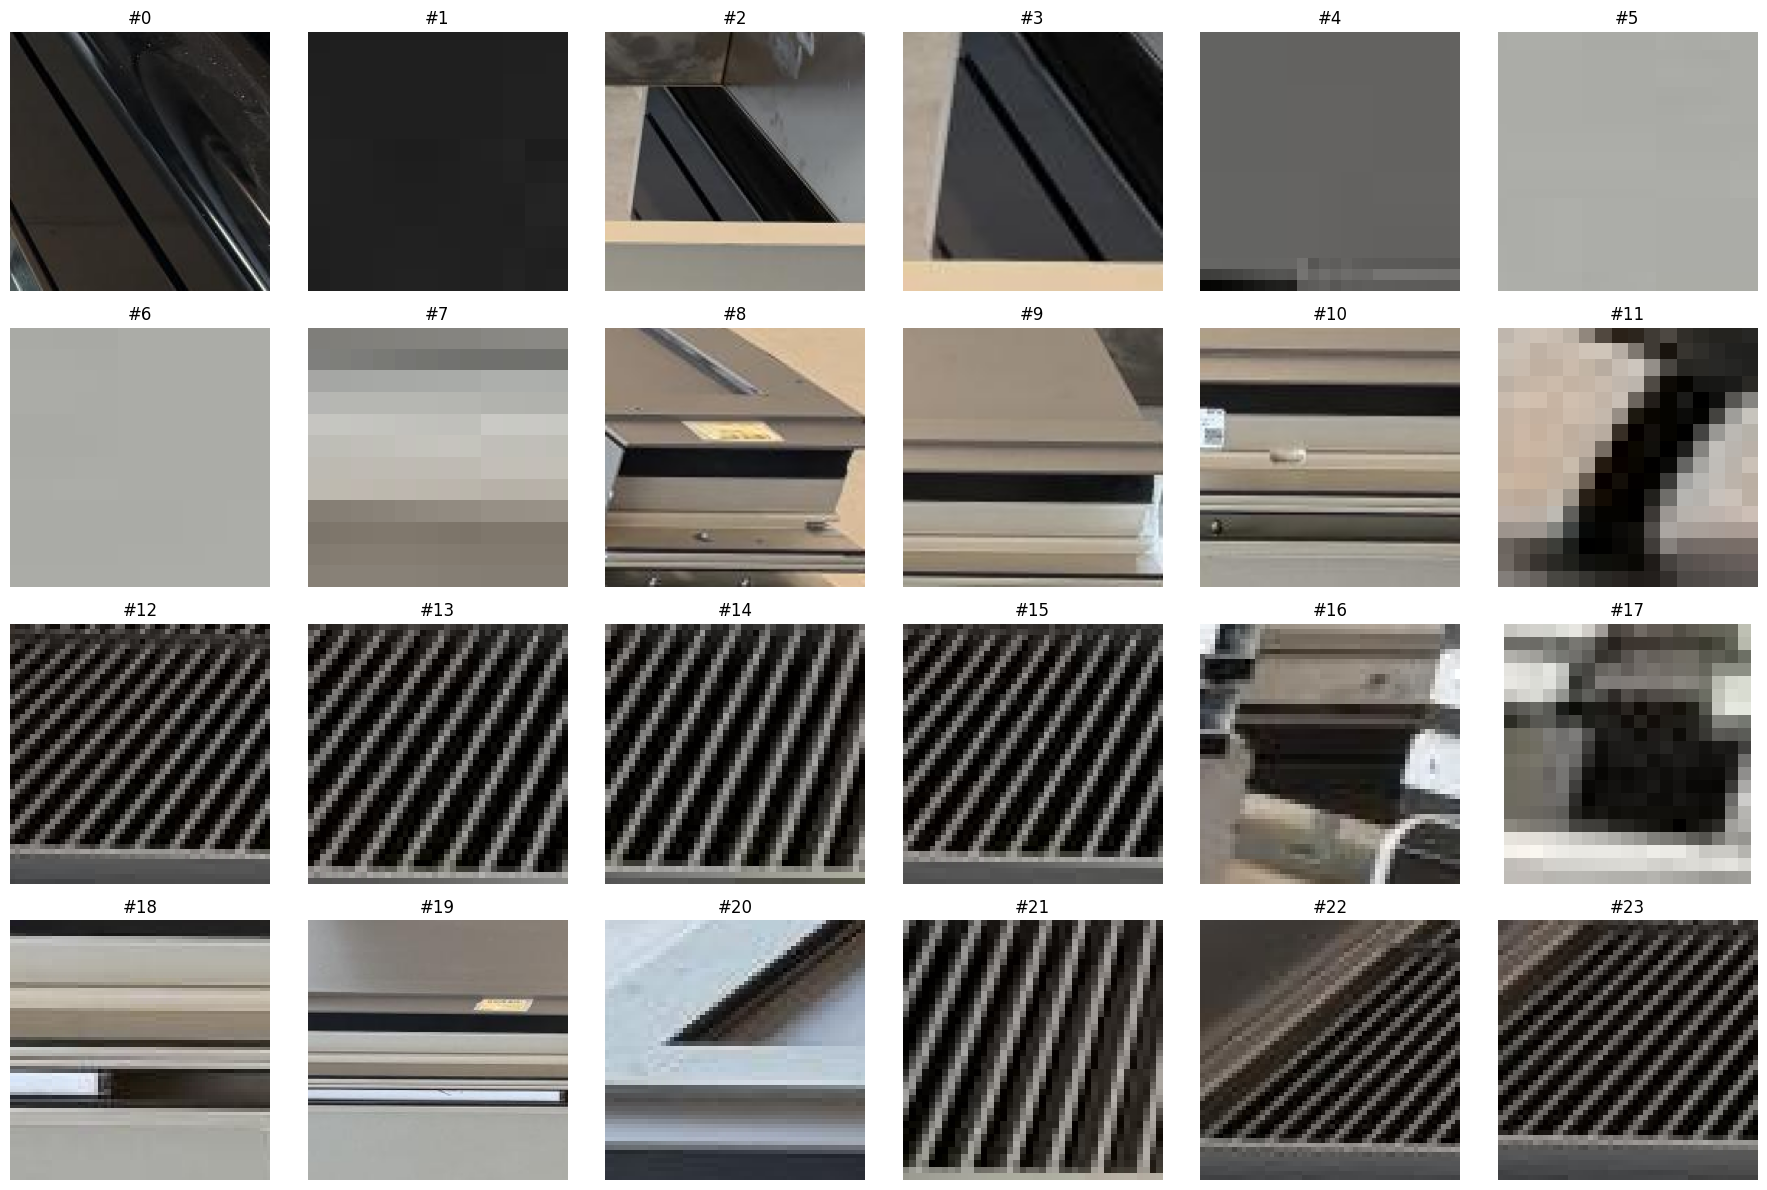

In [17]:
plot_candidate_crops(bgr, candidates, max_crops=24, pad=2.0)


Found: 5 images in C:\Users\anabe\Documents\TRAIN\TRAIN\screws


  0%|          | 0/5 [00:00<?, ?it/s]

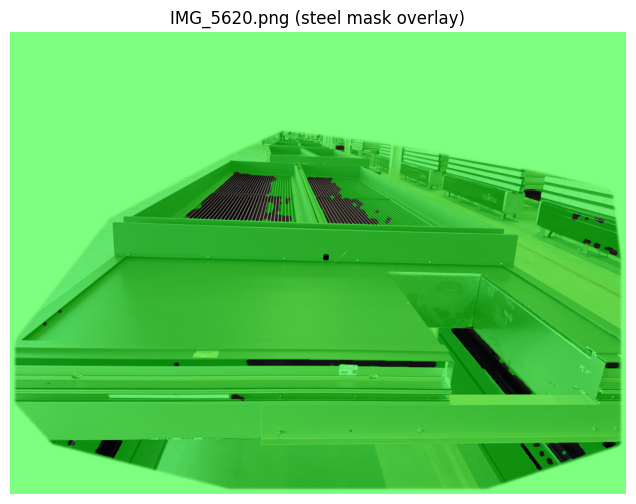


IMG_5620.png: raw=152  steel=152  ring=152  tex=36  FINAL=36


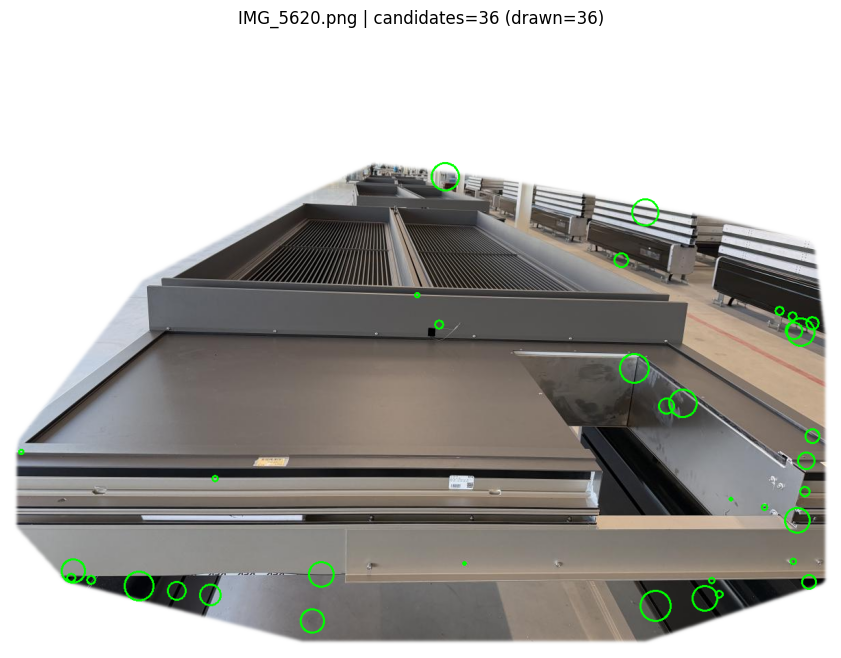

 20%|██        | 1/5 [00:00<00:01,  2.07it/s]

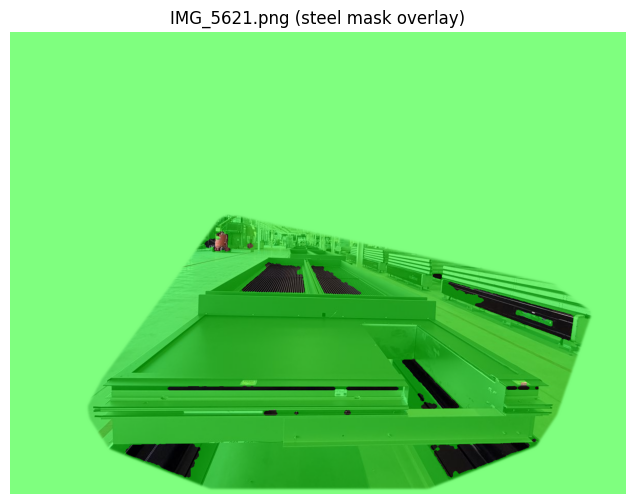


IMG_5621.png: raw=145  steel=145  ring=144  tex=22  FINAL=22


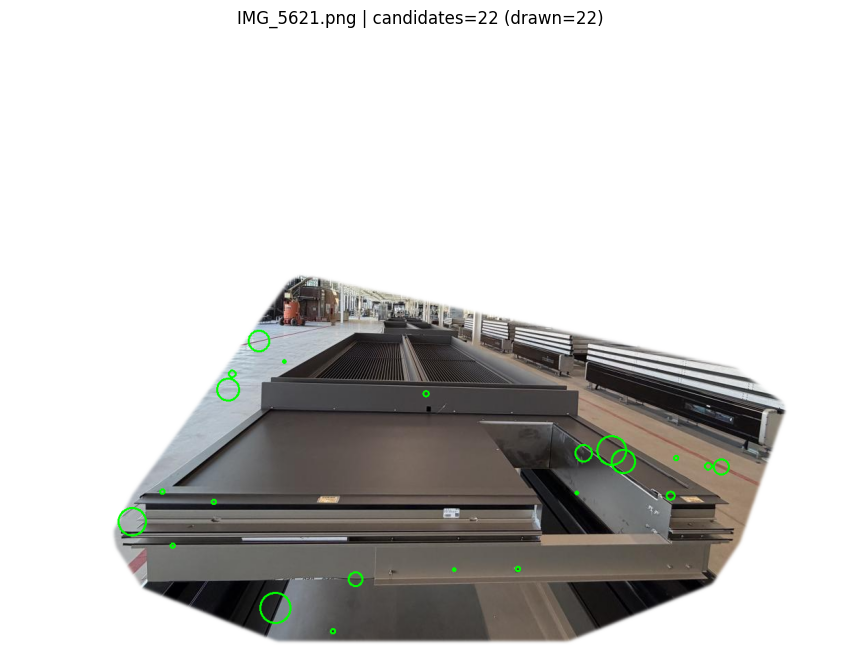

 40%|████      | 2/5 [00:00<00:01,  2.12it/s]


IMG_5622.png: raw=70  steel=70  ring=70  tex=17  FINAL=17


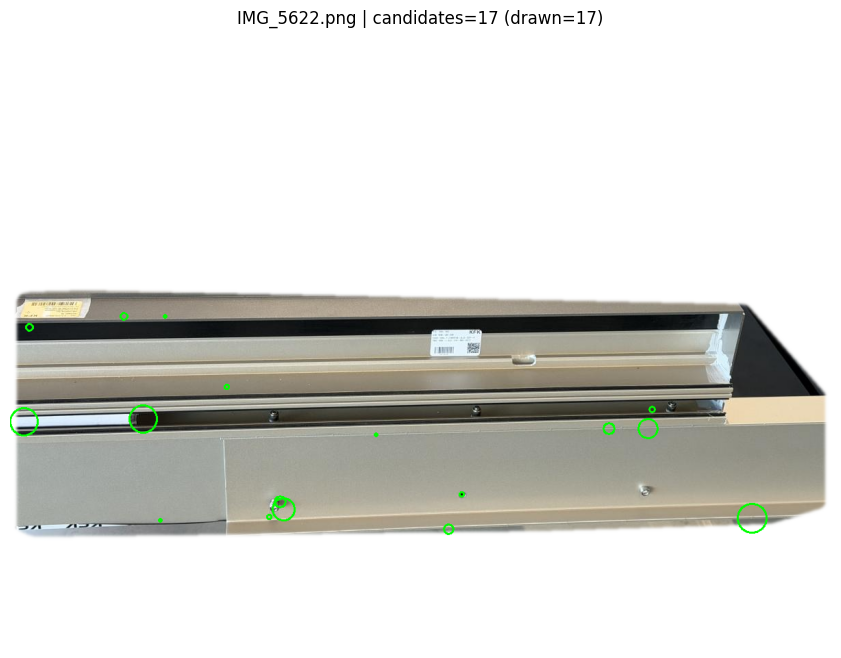

 60%|██████    | 3/5 [00:01<00:00,  2.57it/s]


IMG_5623.png: raw=42  steel=42  ring=42  tex=14  FINAL=14


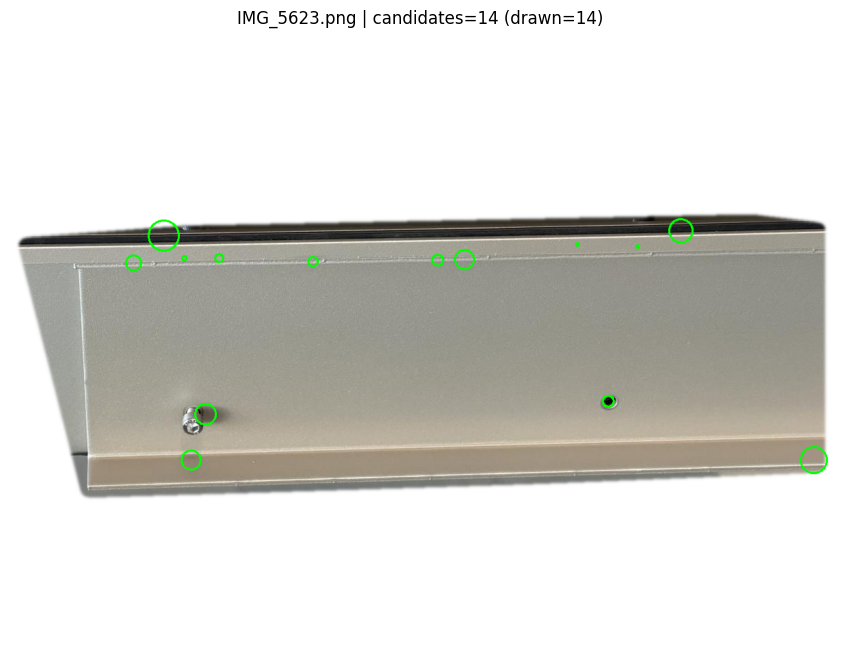

 80%|████████  | 4/5 [00:01<00:00,  2.99it/s]


IMG_5628.png: raw=257  steel=257  ring=256  tex=41  FINAL=41


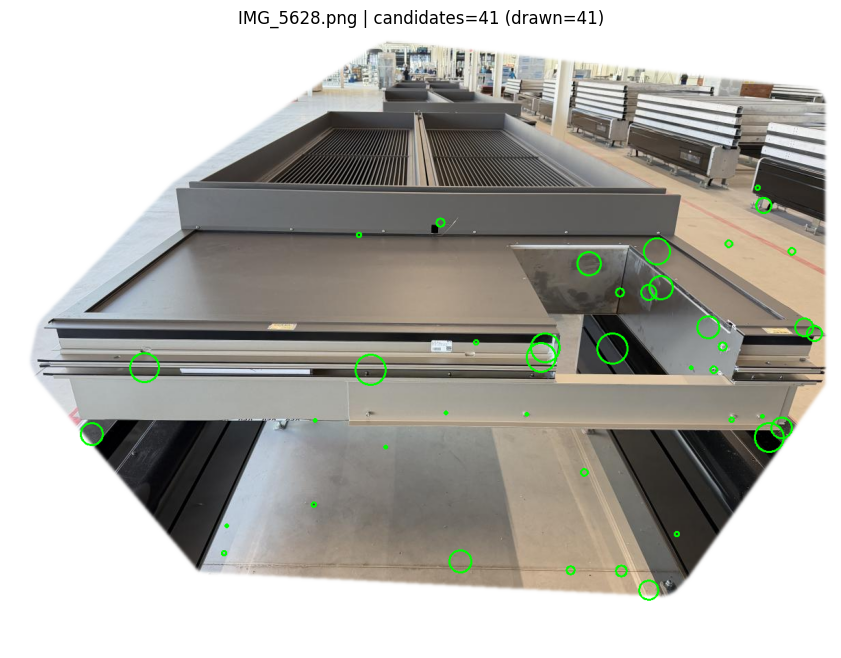

100%|██████████| 5/5 [00:01<00:00,  2.63it/s]

Saved screw_candidates_report_debug.csv


,path,raw,after_steel,after_ring,after_texture,final
4,screws\IMG_5628.png,257,257,256,41,41
0,screws\IMG_5620.png,152,152,152,36,36
1,screws\IMG_5621.png,145,145,144,22,22
2,screws\IMG_5622.png,70,70,70,17,17
3,screws\IMG_5623.png,42,42,42,14,14


In [29]:
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
from pillow_heif import register_heif_opener

register_heif_opener()

# =========================
# Config (LOOSENED so we don't get 0)
# =========================
SCREWS_DIR = Path("../data/raw/screws")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp", ".heic"}

MAX_SHOW = 10
MAX_DRAW = 300

TILE = 1200
OVERLAP = 300

# If screws are tiny in wide shots, you MUST allow small radii:
MIN_R = 2
MAX_R = 22

# Steel thresholds (less strict than last time)
STEEL_MAX_SAT = 95
STEEL_MIN_VAL = 25
STEEL_MAX_VAL = 255
STEEL_MAX_SPREAD = 95

# Hough (more permissive)
HOUGH_DP = 1.2
HOUGH_MINDIST = 10
HOUGH_PARAM1 = 120
HOUGH_PARAM2 = 18   # lower -> more circles

# Blob detector (more permissive)
BLOB_MIN_AREA = 12
BLOB_MAX_AREA = 4000
BLOB_MIN_THRESH = 5
BLOB_MAX_THRESH = 240

# Surround / texture gates (start permissive; we’ll tighten after we see candidates)
RING_MIN_STEEL_FRAC = 0.55
RING_INNER_SCALE = 1.2
RING_OUTER_SCALE = 8.0
TEXTURE_MAX_EDGE_DENSITY = 0.10   # higher -> more permissive

# =========================
# IO
# =========================
def list_images(folder: Path):
    return [p for p in folder.rglob("*") if p.suffix.lower() in EXTS and p.is_file()]

def open_bgr(p: Path):
    pil = Image.open(p).convert("RGB")
    return cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)

# =========================
# Steel mask / patch check
# =========================
def steel_mask(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    S = hsv[:, :, 1]
    V = hsv[:, :, 2]

    m = ((S <= STEEL_MAX_SAT) & (V >= STEEL_MIN_VAL) & (V <= STEEL_MAX_VAL)).astype(np.uint8) * 255

    b, g, r = cv2.split(bgr)
    spread = np.maximum.reduce([cv2.absdiff(r, g), cv2.absdiff(r, b), cv2.absdiff(g, b)])
    m3 = (spread <= STEEL_MAX_SPREAD).astype(np.uint8) * 255
    m = cv2.bitwise_and(m, m3)

    # mild cleanup (not aggressive)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k, iterations=1)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k, iterations=1)
    return m

def is_steel_patch(bgr, x, y, r, pad=2.0):
    H, W = bgr.shape[:2]
    R = int(max(10, r * pad))
    x1, y1 = max(0, x - R), max(0, y - R)
    x2, y2 = min(W, x + R), min(H, y + R)
    patch = bgr[y1:y2, x1:x2]
    if patch.size == 0:
        return False
    m = steel_mask(patch)
    # permissive: only require some steel
    return (m.mean() > 80)

# =========================
# Surrounding ring + texture
# =========================
def steel_surrounding_ring_ok(bgr, x, y, r,
                             inner_scale=RING_INNER_SCALE,
                             outer_scale=RING_OUTER_SCALE,
                             min_steel_frac=RING_MIN_STEEL_FRAC):
    H, W = bgr.shape[:2]
    R1 = int(max(5, r * inner_scale))
    R2 = int(max(10, r * outer_scale))

    x1, y1 = max(0, x - R2), max(0, y - R2)
    x2, y2 = min(W, x + R2), min(H, y + R2)
    patch = bgr[y1:y2, x1:x2]
    if patch.size == 0:
        return False

    h, w = patch.shape[:2]
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    d2 = (yy - cy) ** 2 + (xx - cx) ** 2
    ring = (d2 >= R1*R1) & (d2 <= R2*R2)
    if not ring.any():
        return False

    m = steel_mask(patch)
    steel_frac = (m[ring] > 0).mean()
    return steel_frac >= min_steel_frac

def low_texture_surround(bgr, x, y, r, scale=3.0, max_edge_density=TEXTURE_MAX_EDGE_DENSITY):
    H, W = bgr.shape[:2]
    R = int(max(10, r * scale))
    x1, y1 = max(0, x-R), max(0, y-R)
    x2, y2 = min(W, x+R), min(H, y+R)
    crop = bgr[y1:y2, x1:x2]
    if crop.size == 0:
        return False
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 80, 160)
    return (edges.mean() / 255.0) <= max_edge_density

# =========================
# Tiling / dedup
# =========================
def iter_tiles(bgr):
    H, W = bgr.shape[:2]
    step = TILE - OVERLAP
    for y0 in range(0, H, step):
        for x0 in range(0, W, step):
            y1 = min(H, y0 + TILE)
            x1 = min(W, x0 + TILE)
            y0e = max(0, y1 - TILE)
            x0e = max(0, x1 - TILE)
            yield x0e, y0e, bgr[y0e:y1, x0e:x1]

def dedup(cands, dist_px=10):
    kept = []
    for x, y, r in sorted(cands, key=lambda t: t[2]):  # small-first
        ok = True
        for xx, yy, rr in kept:
            if (x-xx)*(x-xx) + (y-yy)*(y-yy) <= dist_px*dist_px:
                ok = False
                break
        if ok:
            kept.append((x, y, r))
    return kept

# =========================
# Blob detector
# =========================
def build_blob_detector():
    params = cv2.SimpleBlobDetector_Params()
    params.filterByArea = True
    params.minArea = BLOB_MIN_AREA
    params.maxArea = BLOB_MAX_AREA
    params.filterByCircularity = False
    params.filterByInertia = False
    params.filterByConvexity = False
    params.minThreshold = BLOB_MIN_THRESH
    params.maxThreshold = BLOB_MAX_THRESH
    return cv2.SimpleBlobDetector_create(params)

blob_detector = build_blob_detector()

def blob_candidates(tile_bgr, tile_steel):
    gray = cv2.cvtColor(tile_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.bitwise_and(gray, gray, mask=tile_steel)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
    kps = blob_detector.detect(gray)
    out = []
    for kp in kps:
        x, y = kp.pt
        r = max(2, int(kp.size/2))
        if MIN_R <= r <= MAX_R:
            out.append((int(x), int(y), int(r)))
    return out

# =========================
# Hough circles
# =========================
def hough_candidates(tile_bgr, tile_steel, min_r, max_r):
    gray = cv2.cvtColor(tile_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.bitwise_and(gray, gray, mask=tile_steel)
    gray = cv2.GaussianBlur(gray, (7, 7), 0)
    circles = cv2.HoughCircles(
        gray, cv2.HOUGH_GRADIENT,
        dp=HOUGH_DP, minDist=HOUGH_MINDIST,
        param1=HOUGH_PARAM1, param2=HOUGH_PARAM2,
        minRadius=min_r, maxRadius=max_r
    )
    out = []
    if circles is not None:
        circles = np.round(circles[0]).astype(int)
        for x, y, r in circles:
            r = max(2, int(r))
            if MIN_R <= r <= MAX_R:
                out.append((x, y, r))
    return out

# =========================
# Visualization helpers
# =========================
def show_mask_overlay(bgr, mask, title=""):
    overlay = bgr.copy()
    overlay[mask > 0] = (0.5 * overlay[mask > 0] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
    plt.figure(figsize=(14, 6))
    plt.title(title + " (steel mask overlay)")
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

def plot_candidates(bgr, circles, title=""):
    vis = bgr.copy()
    for (x, y, r) in circles[:MAX_DRAW]:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 2)
    plt.figure(figsize=(14, 8))
    plt.title(f"{title} | candidates={len(circles)} (drawn={min(len(circles), MAX_DRAW)})")
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# =========================
# RUN (with DEBUG COUNTS)
# =========================
paths = list_images(SCREWS_DIR)
print("Found:", len(paths), "images in", SCREWS_DIR.resolve())

results = []
shown = 0

for p in tqdm(paths):
    bgr = open_bgr(p)

    raw = []
    steel_ok = 0
    ring_ok = 0
    tex_ok = 0

    # (optional) show steel mask overlay for the first few images
    if shown < 2:
        m_full = steel_mask(bgr)
        show_mask_overlay(bgr, m_full, title=p.name)

    for x0, y0, tile in iter_tiles(bgr):
        m = steel_mask(tile)
        hc = hough_candidates(tile, m, MIN_R, MAX_R)
        bc = blob_candidates(tile, m)
        for (x, y, r) in (hc + bc):
            raw.append((x + x0, y + y0, r))

    raw = dedup(raw, dist_px=10)

    filtered = []
    for (x, y, r) in raw:
        if not is_steel_patch(bgr, x, y, r):
            continue
        steel_ok += 1

        if not steel_surrounding_ring_ok(bgr, x, y, r):
            continue
        ring_ok += 1

        if not low_texture_surround(bgr, x, y, r):
            continue
        tex_ok += 1

        filtered.append((x, y, r))

    results.append({
        "path": str(p),
        "raw": len(raw),
        "after_steel": steel_ok,
        "after_ring": ring_ok,
        "after_texture": tex_ok,
        "final": len(filtered),
    })

    if shown < MAX_SHOW:
        print(f"\n{p.name}: raw={len(raw)}  steel={steel_ok}  ring={ring_ok}  tex={tex_ok}  FINAL={len(filtered)}")
        plot_candidates(bgr, filtered, title=p.name)
        shown += 1

df = pd.DataFrame(results)
df.to_csv("../outputs/screw_candidates_report_debug.csv", index=False)
print("Saved screw_candidates_report_debug.csv")
display(df.sort_values("final", ascending=False).head(10))
